Import thư viện và thiết lập môi trường

In [33]:
from pathlib import Path
import json
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

RANDOM_SEED = 42
POSITIVE_THRESHOLD = 4.0

np.random.seed(RANDOM_SEED)

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Phase 1 environment ready!")

Pandas: 2.3.3
NumPy: 2.5.4
Phase 1 environment ready!


Xác định thư mục dự án

In [34]:
def find_project_root():
    current = Path.cwd().resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "src" / "data").is_dir():
            return candidate
    colab_root = Path("/content/movie-dss")
    if (colab_root / "src" / "data").is_dir():
        return colab_root
    raise FileNotFoundError("Cannot find project root")

PROJECT_ROOT = find_project_root()

RAW_DIR = PROJECT_ROOT / "data" / "raw"
REPORT_DIR = PROJECT_ROOT / "experiments" / "eda"
FIGURE_DIR = REPORT_DIR / "figures"

for directory in [RAW_DIR, REPORT_DIR, FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw data:", RAW_DIR)
assert (RAW_DIR / "ml-1m" / "movies.csv").exists(), "Missing ml-1m/movies.csv"
assert (RAW_DIR / "ml-1m" / "ratings.csv").exists(), "Missing ml-1m/ratings.csv"
print("Reports:", REPORT_DIR)

Project root: E:\SV\NAM4-KY1\1. DSS\HGNN-Attention-Recommender
Raw data: E:\SV\NAM4-KY1\1. DSS\HGNN-Attention-Recommender\data\raw
Reports: E:\SV\NAM4-KY1\1. DSS\HGNN-Attention-Recommender\experiments\eda


Đọc dữ liệu

In [35]:
dataset_dir = RAW_DIR / "ml-1m"
users = pd.read_csv(dataset_dir / "users.csv")
ratings = pd.read_csv(dataset_dir / "ratings.csv")
movies = pd.read_csv(dataset_dir / "movies.csv")

datasets = {
    "ratings": ratings,
    "movies": movies,
    "users": users,
}

for name, df in datasets.items():
    print(f"\n{name.upper()}")
    print("Shape:", df.shape)
    display(df.head())


RATINGS
Shape: (1000209, 4)


,userId,movieId,rating,timestamp
0,1,1193,5.0,978300760
1,1,661,3.0,978302109
2,1,914,3.0,978301968
3,1,3408,4.0,978300275
4,1,2355,5.0,978824291



MOVIES
Shape: (3883, 3)


,movieId,title,genres
0,1,Toy Story (1995),Animation|Children|Comedy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy



USERS
Shape: (6040, 5)


,userId,gender,age,occupation,zipCode
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117
3,4,M,45,7,02460
4,5,M,25,20,55455


Thống kê tổng quan

In [36]:
num_users = ratings["userId"].nunique()
num_movies = movies["movieId"].nunique()
num_rated_movies = ratings["movieId"].nunique()
num_ratings = len(ratings)

positive_ratings = ratings[
    ratings["rating"] >= POSITIVE_THRESHOLD
]

num_positive = len(positive_ratings)

total_possible = num_users * num_movies
density = num_ratings / total_possible
sparsity = 1 - density

summary = {
    "num_users": int(num_users),
    "num_movies": int(num_movies),
    "num_rated_movies": int(num_rated_movies),
    "num_ratings": int(num_ratings),
    "num_positive_ratings": int(num_positive),
    "positive_ratio": float(num_positive / num_ratings),
    "density": float(density),
    "sparsity": float(sparsity),
}

display(pd.DataFrame(
    summary.items(),
    columns=["Metric", "Value"]
))

,Metric,Value
0,num_users,6.040000e+03
1,num_movies,3.883000e+03
2,num_rated_movies,3.706000e+03
3,num_ratings,1.000209e+06
4,num_positive_ratings,5.752810e+05
5,positive_ratio,5.751608e-01
6,density,4.264680e-02
7,sparsity,9.573532e-01


Kiểm tra missing values và duplicates

In [37]:
for name, df in datasets.items():
    print(f"\n===== {name.upper()} =====")

    print("Missing values:")
    display(df.isnull().sum())

    print("Exact duplicate rows:", df.duplicated().sum())

print(
    "Duplicate user-movie pairs:",
    ratings.duplicated(
        subset=["userId", "movieId"]
    ).sum()
)

print(
    "Ratings referencing unknown movies:",
    (~ratings["movieId"].isin(movies["movieId"])).sum()
)

print(
    "Invalid rating values:",
    (~ratings["rating"].between(0.5, 5.0)).sum()
)


===== RATINGS =====
Missing values:


userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Exact duplicate rows: 0

===== MOVIES =====
Missing values:


movieId    0
title      0
genres     0
dtype: int64

Exact duplicate rows: 0

===== USERS =====
Missing values:


userId        0
gender        0
age           0
occupation    0
zipCode       0
dtype: int64

Exact duplicate rows: 0
Duplicate user-movie pairs: 0
Ratings referencing unknown movies: 0
Invalid rating values: 0


Kiểm tra timestamp

In [38]:
ratings["datetime"] = pd.to_datetime(
    ratings["timestamp"],
    unit="s",
    utc=True
)

print("Earliest interaction:", ratings["datetime"].min())
print("Latest interaction:", ratings["datetime"].max())

print("Missing timestamps:", ratings["timestamp"].isna().sum())

print(
    "Duplicate timestamps:",
    ratings["timestamp"].duplicated().sum()
)

display(
    ratings.sort_values("timestamp").head(10)
)

Earliest interaction: 2000-04-25 23:05:32+00:00
Latest interaction: 2003-02-28 17:49:50+00:00
Missing timestamps: 0
Duplicate timestamps: 541754


,userId,movieId,rating,timestamp,datetime
1000138,6040,858,4.0,956703932,2000-04-25 23:05:32+00:00
999873,6040,593,5.0,956703954,2000-04-25 23:05:54+00:00
1000153,6040,2384,4.0,956703954,2000-04-25 23:05:54+00:00
1000007,6040,1961,4.0,956703977,2000-04-25 23:06:17+00:00
1000192,6040,2019,5.0,956703977,2000-04-25 23:06:17+00:00
999980,6040,3505,4.0,956704056,2000-04-25 23:07:36+00:00
999967,6040,3111,5.0,956704056,2000-04-25 23:07:36+00:00
999920,6040,213,5.0,956704056,2000-04-25 23:07:36+00:00
999877,6040,1419,3.0,956704056,2000-04-25 23:07:36+00:00
999868,6040,573,4.0,956704056,2000-04-25 23:07:36+00:00


Phân phối Rating

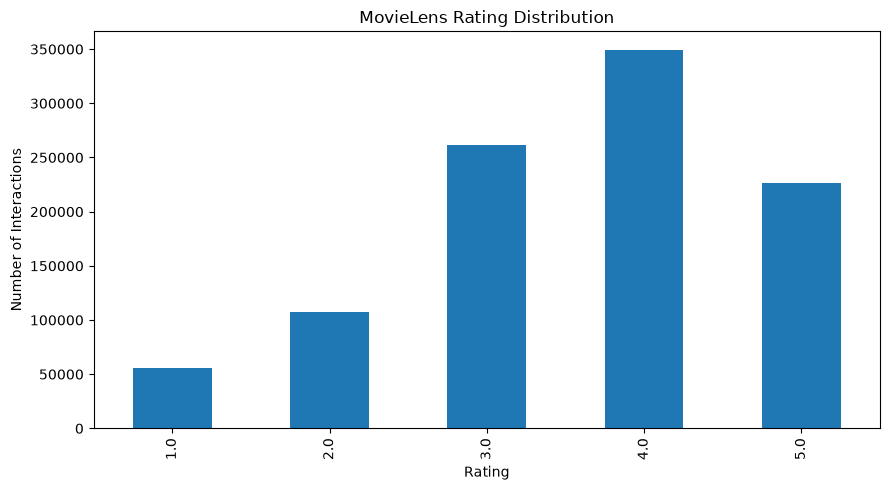

In [39]:
rating_counts = ratings["rating"].value_counts().sort_index()

plt.figure(figsize=(9, 5))
rating_counts.plot(kind="bar")

plt.title("MovieLens Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Interactions")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "rating_distribution.png",
    dpi=150
)
plt.show()

Mức độ hoạt động của User

count    6040.000000
mean      165.597517
std       192.747029
min        20.000000
25%        44.000000
50%        96.000000
75%       208.000000
max      2314.000000
dtype: float64
Users with fewer than 1 ratings: 0
Users with fewer than 5 ratings: 0
Users with fewer than 10 ratings: 0
Users with fewer than 20 ratings: 0


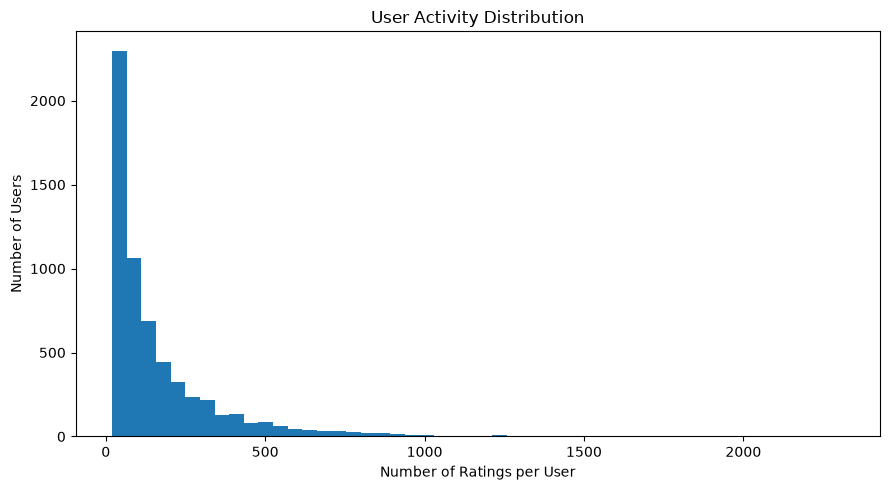

In [40]:
user_activity = ratings.groupby("userId").size()

print(user_activity.describe())

for threshold in [1, 5, 10, 20]:
    count = (user_activity < threshold).sum()
    print(f"Users with fewer than {threshold} ratings: {count}")

plt.figure(figsize=(9, 5))
plt.hist(user_activity, bins=50)

plt.title("User Activity Distribution")
plt.xlabel("Number of Ratings per User")
plt.ylabel("Number of Users")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "user_activity.png",
    dpi=150
)
plt.show()

Mức độ phổ biến của Movie

In [41]:
movie_activity = ratings.groupby("movieId").size()

print(movie_activity.describe())

print("Top 10 most rated movies:")

top_movies = (
    movie_activity
    .sort_values(ascending=False)
    .head(10)
    .rename("rating_count")
    .reset_index()
    .merge(movies, on="movieId", how="left")
)

display(top_movies)

count    3706.000000
mean      269.889099
std       384.047838
min         1.000000
25%        33.000000
50%       123.500000
75%       350.000000
max      3428.000000
dtype: float64
Top 10 most rated movies:


,movieId,rating_count,title,genres
0,2858,3428,American Beauty (1999),Comedy|Drama
1,260,2991,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Fantasy|Sci-Fi
2,1196,2990,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Drama|Sci-Fi|War
3,1210,2883,Star Wars: Episode VI - Return of the Jedi (1983),Action|Adventure|Romance|Sci-Fi|War
4,480,2672,Jurassic Park (1993),Action|Adventure|Sci-Fi
5,2028,2653,Saving Private Ryan (1998),Action|Drama|War
6,589,2649,Terminator 2: Judgment Day (1991),Action|Sci-Fi|Thriller
7,2571,2590,"Matrix, The (1999)",Action|Sci-Fi|Thriller
8,1270,2583,Back to the Future (1985),Comedy|Sci-Fi
9,593,2578,"Silence of the Lambs, The (1991)",Drama|Thriller


Phân tích Genre

genres
Drama          1603
Comedy         1200
Action          503
Thriller        492
Romance         471
Horror          343
Adventure       283
Sci-Fi          276
Children        251
Crime           211
War             143
Documentary     127
Musical         114
Mystery         106
Animation       105
Fantasy          68
Western          68
Film-Noir        44
Name: count, dtype: int64

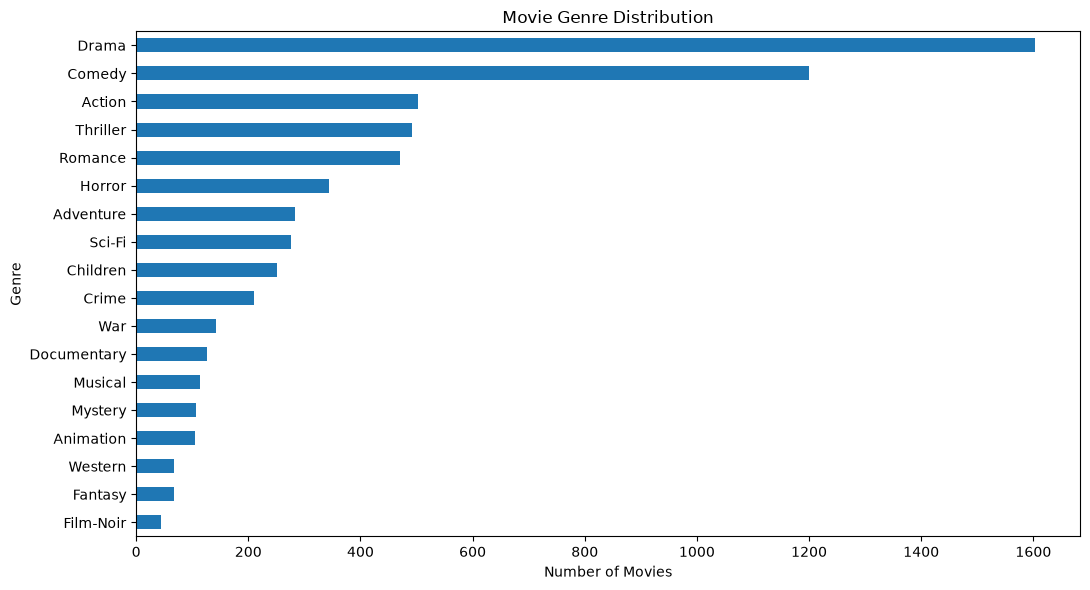

In [42]:
genre_counts = (
    movies["genres"]
    .fillna("(no genres listed)")
    .str.split("|", regex=False)
    .explode()
    .value_counts()
)

display(genre_counts)

plt.figure(figsize=(11, 6))
genre_counts.sort_values().plot(kind="barh")

plt.title("Movie Genre Distribution")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "genre_distribution.png",
    dpi=150
)
plt.show()

Phân tích tương tác theo thời gian

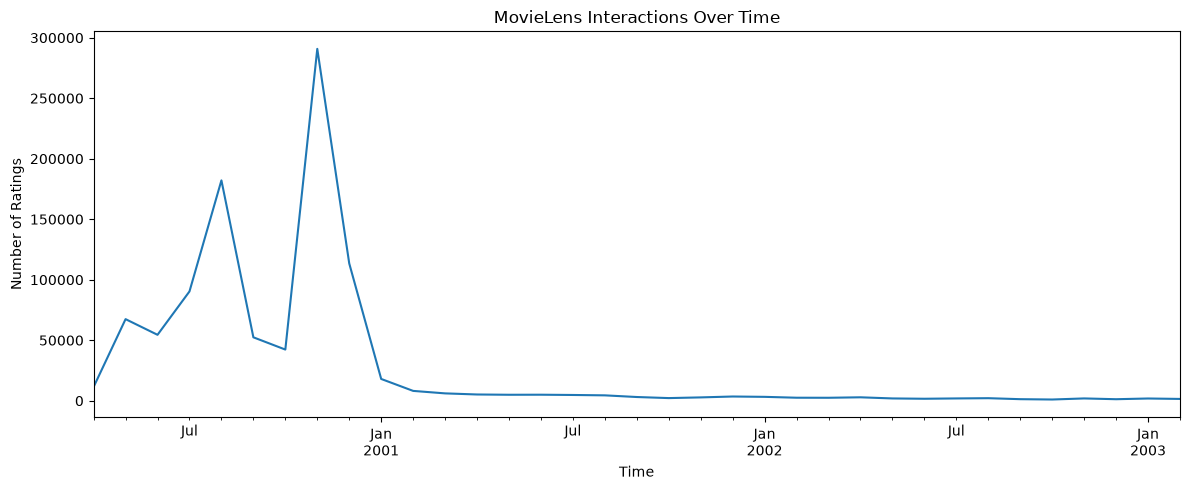

In [43]:
monthly_interactions = (
    ratings
    .set_index("datetime")
    .resample("MS")
    .size()
)

plt.figure(figsize=(12, 5))
monthly_interactions.plot()

plt.title("MovieLens Interactions Over Time")
plt.xlabel("Time")
plt.ylabel("Number of Ratings")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "interactions_over_time.png",
    dpi=150
)
plt.show()

Tạo báo cáo chất lượng dữ liệu

In [44]:
quality_report = {
    **summary,
    "rating_min": float(ratings["rating"].min()),
    "rating_max": float(ratings["rating"].max()),
    "earliest_timestamp": ratings["datetime"].min().isoformat(),
    "latest_timestamp": ratings["datetime"].max().isoformat(),
    "duplicate_user_movie_pairs": int(
        ratings.duplicated(["userId", "movieId"]).sum()
    ),
    "unknown_movie_references": int(
        (~ratings["movieId"].isin(movies["movieId"])).sum()
    ),
    "missing_values": {
        name: {
            column: int(count)
            for column, count in df.isnull().sum().items()
        }
        for name, df in datasets.items()
    },
    "user_activity": {
        key: float(value)
        for key, value in user_activity.describe().items()
    },
    "movie_activity": {
        key: float(value)
        for key, value in movie_activity.describe().items()
    },
    "genre_counts": {
        str(key): int(value)
        for key, value in genre_counts.items()
    },
}

report_path = REPORT_DIR / "data_quality_report.json"

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(quality_report, f, indent=2, ensure_ascii=False)

print("Saved:", report_path)

Saved: E:\SV\NAM4-KY1\1. DSS\HGNN-Attention-Recommender\experiments\eda\data_quality_report.json


Kiểm thử Phase 1

In [45]:
assert len(ratings) > 0, "Ratings dataset is empty"
assert len(movies) > 0, "Movies dataset is empty"

assert ratings["userId"].notna().all()
assert ratings["movieId"].notna().all()
assert ratings["rating"].notna().all()
assert ratings["timestamp"].notna().all()

assert ratings["rating"].between(0.5, 5.0).all()

assert set(ratings["movieId"]).issubset(
    set(movies["movieId"])
), "Unknown movie IDs detected"

assert 0 <= density <= 1
assert 0 <= sparsity <= 1

assert report_path.exists()

expected_figures = [
    "rating_distribution.png",
    "user_activity.png",
    "genre_distribution.png",
    "interactions_over_time.png",
]

for filename in expected_figures:
    assert (FIGURE_DIR / filename).exists(), (
        f"Missing figure: {filename}"
    )

print("All Phase 1 tests passed!")

All Phase 1 tests passed!


Đóng gói kết quả

In [ ]:
import shutil
from google.colab import files

archive_path = shutil.make_archive(
    "/content/phase1_eda_results",
    "zip",
    root_dir=PROJECT_ROOT,
    base_dir="experiments/eda"
)

files.download(archive_path)